<a href="https://colab.research.google.com/github/eparrama/S5_la_mobil_econ/blob/main/S5_ladb_mobility_economy_project_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Introducción

El objetivo es **evaluar cómo la movilidad urbana se relaciona con la productividad económica en las principales ciudades latinoamericanas**.
Para ello utilizamos datos reales de TomTom Traffic Index y OECD Cities, que vamos a limpiar, combinar y analizar para identificar en qué ciudades conviene invertir en infraestructura de transporte.

## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarse con la estructura de ambos datasets**.
En esta etapa, validaremos que los archivos se carguen correctamente, conoceremos sus columnas y tipos de datos, y detectaremos posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯Objetivo:**
Importar las librerías necesarias, cargar los archivos CSV en DataFrames y realizar una revisión preliminar para entender su contenido.

**Instrucciones:**
- Importar las librerías `pandas`, `numpy`, `seaborn` y `matplotlib.pyplot`.
- Cargar los archivos usando `pd.read_csv()`:
  - `'/content/tomtom_traffic.csv'`
  - `/content/oecd_city_economy.csv` `.
- Guardar los DataFrames en las variables `traffic` y `eco`.
- Mostrar las primeras 5 filas de cada DataFrame.


In [27]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [28]:
# cargar archivos
traffic = pd.read_csv('/content/tomtom_traffic.csv')
eco = pd.read_csv('/content/oecd_city_economy.csv')

In [29]:
# mostrar las primeras 5 filas de traffic
traffic.head(5)

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232
3,ARE,abu-dhabi,2025-01-13 01:46:30.001,8.2,2.0,4.1,2.0,2.0,2025-01-06 01:46:30.000,7.723808,7.899046,-0.175238
4,ARE,abu-dhabi,2025-01-13 00:01:30.000,1.1,1.0,0.2,1.0,1.0,2025-01-06 00:01:30.000,8.336363,8.604379,-0.268016


In [30]:
# mostrar las primeras 5 filas de eco
eco.head(5)

,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"
3,2023,brasilia,Brazil,"15.999,00",8.3%,"13,50","4,70"
4,2023,salvador,Brazil,"8.761,00",13.1%,"16,00","3,90"



---

## 🧩Paso 2: Explorar, limpiar y preparar los datos

Antes de combinar los datasets, inspeccionar su estructura, tipos de datos, columnas y valores faltantes.
Anotar las columnas que necesiten limpieza y luego estandarizar los nombres de columnas.

### 2.1 Explorar la estructura y tipos de datos

**🎯Objetivo:**
Identificar columnas con tipos incorrectos, distribución y nulos, anotar las columnas que requieren conversión.

**Instrucciones:**

- Usar `.info()` para conocer la estructura de ambos DataFrames.
- Mostrar los primeros 3 renglones de cada DF.
- Identificar si los detalles de cada DF estan bien o si requieren correcciones y escribir las conclusiones en el bloque Markdown.
  - ¿Hay columnas que requieren conversión?¿ Cuáles son? ¿Que tipo de dato ienen y cuál deberían de tener?
  - ¿Hay datos ausentes en alguna columna?


In [31]:
# Examinar la estructura de traffic
traffic.info()
traffic.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  object 
 1   City                            1004464 non-null  object 
 2   UpdateTimeUTC                   1004464 non-null  object 
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  object 
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       1004464 non-null  float64
dtype

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232


En la estructura del DF traffic, se observa que:
- Las columnas `UpdateTimeUTC` y `UpdateTimeUTCWeekAgo` son de tipo Object (texto)
- Hay que pasarlas a fecha (datetime)

In [32]:
# Examinar la estructura de eco
eco.info()
eco.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Year             30 non-null     int64 
 1   City             30 non-null     object
 2   Country          30 non-null     object
 3   City GDP/capita  30 non-null     object
 4   Unemployment %   30 non-null     object
 5   PM2.5 (μg/m³)    30 non-null     object
 6   Population (M)   30 non-null     object
dtypes: int64(1), object(6)
memory usage: 1.8+ KB


,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"


In [33]:
# Examinar la estructura de eco
eco.info()
eco.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Year             30 non-null     int64 
 1   City             30 non-null     object
 2   Country          30 non-null     object
 3   City GDP/capita  30 non-null     object
 4   Unemployment %   30 non-null     object
 5   PM2.5 (μg/m³)    30 non-null     object
 6   Population (M)   30 non-null     object
dtypes: int64(1), object(6)
memory usage: 1.8+ KB


,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"


En la estructura del DF eco, se observa que:
- Las columnas `City GDP/capita`, `Unemployment %`,´PM2.5 (μg/m³)´ y 'Population' son object
- Hay que pasarlas a numéricas

### 2.2 Renombrar columnas

**🎯Objetivo:**
Estandarizar los nombres de columnas para evitar errores y facilitar la unión de los datasets.

**Instrucciones:**

- Cambia los nombres de las columnas para que tengan el formato `snake_case`.
    - `Country` → `country`
    - `UpdateTimeUTC` → `update_time_utc`
- Verificar que los cambios se hayan aplicado correctamente usando `.columns`.


In [34]:
# Estandarizar los nombres de las columnas de traffic
traffic = traffic.rename(columns={'Country' : 'country', 'City' : 'city',
                                  'UpdateTimeUTC' : 'update_time_utc',
                                  'JamsDelay' : 'jams_delay',
                                  'TrafficIndexLive' : 'traffic_index_live',
                                  'JamsLengthInKms' : 'jams_length_kms',
                                  'JamsCount' : 'jams_count',
                                  'TrafficIndexWeekAgo' : 'traffic_index_week_ago',
                                  'UpdateTimeUTCWeekAgo': 'update_time_utc_week_ago',
                                  'TravelTimeLivePer10KmsMins' : 'travel_time_live_per_10kms_mins',
                                  'TravelTimeHistoricPer10KmsMins' : 'travel_time_hist_per_10kms_mins',
                                  'MinsDelay' : 'mins_delay'})
# verificar cambios
traffic.columns

Index(['country', 'city', 'update_time_utc', 'jams_delay',
       'traffic_index_live', 'jams_length_kms', 'jams_count',
       'traffic_index_week_ago', 'update_time_utc_week_ago',
       'travel_time_live_per_10kms_mins', 'travel_time_hist_per_10kms_mins',
       'mins_delay'],
      dtype='object')

In [35]:
# Estandarizar los nombres de las columnas de eco
eco = eco.rename(columns={'Year' : 'year', 'City' : 'city', 'Country' : 'country',
                          'City GDP/capita': 'city_gdp_capita',
                          'Unemployment %' : 'unemployment_pct', 'PM2.5 (μg/m³)' : 'pm25',
                          'Population (M)' : 'population_m'})
# verificar cambios
eco.columns

Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm25', 'population_m'],
      dtype='object')


### 2.3 Corregir formatos numéricos y de fecha

**🎯Objetivo:**
Asegurar que las columnas de fechas y valores numéricos estén en formatos correctos para permitir análisis, cálculos y comparaciones precisas.

**Instrucciones:**

- Convertir las columnas de fecha de `traffic` a formato `datetime`. Hacer el cambio a prueba de errores.
- En el dataset `eco`, limpiar los valores numéricos:
    - En `city_gdp_capita`: eliminar separadores de miles (`.`) y reemplazar las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `unemployment_pct`: eliminar el símbolo de porcentaje (`%`) y reemplazar las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `population_m`: reemplazar las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
- Finalmente, crear una nueva columna llamada `population` multiplicando `population_m` por 1,000,000 para obtener la población total.


In [36]:
# Convertir las columnas de traffic a tipo fecha con pd.to_datetime()
traffic['update_time_utc'] = pd.to_datetime(traffic['update_time_utc'],errors='coerce',utc=True)
traffic['update_time_utc_week_ago'] = pd.to_datetime(traffic['update_time_utc_week_ago'],errors='coerce',utc=True)
# verificar el cambio
traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                           Non-Null Count    Dtype              
---  ------                           --------------    -----              
 0   country                          1004464 non-null  object             
 1   city                             1004464 non-null  object             
 2   update_time_utc                  1004464 non-null  datetime64[ns, UTC]
 3   jams_delay                       1004464 non-null  float64            
 4   traffic_index_live               1004464 non-null  float64            
 5   jams_length_kms                  1004464 non-null  float64            
 6   jams_count                       1004464 non-null  float64            
 7   traffic_index_week_ago           1004464 non-null  float64            
 8   update_time_utc_week_ago         1004464 non-null  datetime64[ns, UTC]
 9   travel_time_live_per_10kms_mins  1004464 non-n

In [37]:
# Limpia separadores y convierte columnas numéricas en eco
eco['city_gdp_capita'] = eco['city_gdp_capita'].astype(str).str.replace('.', '').str.replace(',', '.').astype(float)
eco['unemployment_pct'] = eco['unemployment_pct'].astype(str).str.replace('%', '').str.replace(',', '.').astype(float)
eco['population_m'] = eco['population_m'].astype(str).str.replace(',','.').astype(float)
# Calcula la población total en unidades absolutas (Multiplica * 1000000)
eco['population'] = eco['population_m']*1000000
# verificar el cambio
eco.info()
eco.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              30 non-null     int64  
 1   city              30 non-null     object 
 2   country           30 non-null     object 
 3   city_gdp_capita   30 non-null     float64
 4   unemployment_pct  30 non-null     float64
 5   pm25              30 non-null     object 
 6   population_m      30 non-null     float64
 7   population        30 non-null     float64
dtypes: float64(4), int64(1), object(3)
memory usage: 2.0+ KB


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m,population
0,2023,buenos-aires,Argentina,15782.0,6.2,"15,2",15.3,15300000.0
1,2023,sao-paulo,Brazil,14475.0,9.1,"29,50",22.5,22500000.0
2,2023,rio-de-janeiro,Brazil,13142.0,9.8,"19,10",13.6,13600000.0



---

## 🧩Paso 3: Extraer año y filtrar

Extraer el año permite filtrar la información y trabajar solo con el período más reciente y relevante.

### 3.1 Extraer columna año y filtrar 2024

**🎯Objetivo**
Identificar el año de cada registro y mantener solo los registros del 2024.

**Intrucciones**

- Como el DataFrame `traffic` no tiene una columna de año, utiliza el atributo `.dt.year` sobre su columna de fecha para crear una nueva columna llamada `year`.
- Filtra las filas donde el año sea **2024**.
- Utiliza `.copy()` para crear dos nuevos DataFrames (`traffic_2024` y `eco_2024`) para evitar modificar el dataset original.

In [38]:
# Extraer el año de las fechas en update_time_utc
traffic['year'] = traffic['update_time_utc'].dt.year
# Verificar cambio
traffic.head(3)

,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,mins_delay,year
0,ARE,abu-dhabi,2025-01-13 04:01:30.001000+00:00,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30+00:00,11.614767,10.265330,1.349437,2025
1,ARE,abu-dhabi,2025-01-13 03:46:00+00:00,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001000+00:00,11.003180,10.031544,0.971635,2025
2,ARE,abu-dhabi,2025-01-13 02:46:30+00:00,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30+00:00,8.196278,8.196510,-0.000232,2025


In [39]:
# Filtra los registros del año 2024
traffic_2024 = traffic[traffic['year']==2024].copy()
eco_2024 = eco[eco['year']==2024].copy()
# Revisar dataframes nuevos
display(traffic_2024.head())
display(eco_2024.head())


,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,mins_delay,year
302,ARE,abu-dhabi,2024-12-31 23:01:30+00:00,12.9,5.0,2.5,5.0,2.0,2024-12-24 23:01:30.001000+00:00,8.560399,8.519634,0.040765,2024
303,ARE,abu-dhabi,2024-12-31 22:01:30+00:00,136.0,21.0,20.6,32.0,3.0,2024-12-24 22:01:30+00:00,10.355732,9.049445,1.306286,2024
304,ARE,abu-dhabi,2024-12-31 21:16:30+00:00,455.2,31.0,40.4,72.0,4.0,2024-12-24 21:01:30+00:00,11.456878,9.305174,2.151704,2024
305,ARE,abu-dhabi,2024-12-31 20:01:00.001000+00:00,399.4,27.0,38.0,75.0,6.0,2024-12-24 20:01:30.001000+00:00,11.670062,9.952811,1.717252,2024
306,ARE,abu-dhabi,2024-12-31 19:46:00+00:00,366.4,28.0,39.8,82.0,9.0,2024-12-24 19:01:00+00:00,11.686322,10.008469,1.677853,2024


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m,population
15,2024,buenos-aires,Argentina,18117.0,7.2,"14,50",15.4,15400000.0
16,2024,sao-paulo,Brazil,14703.0,8.5,"28,00",22.6,22600000.0
17,2024,rio-de-janeiro,Brazil,13349.0,9.2,"18,40",13.7,13700000.0
18,2024,brasilia,Brazil,16251.0,7.8,"12,80",4.8,4800000.0
19,2024,salvador,Brazil,8899.0,12.4,"15,20",3.9,3900000.0



---

## 🧩Paso 4: Analizar y resumir datos de movilidad

Como el dataset de tráfico contiene **múltiples registros por ciudad**. En esta parte, calcular los promedios anuales por ciudad para simplificar el análisis y obtener una visión más clara de las tendencias generales.

### 4.1 Calcular promedios de tráfico por ciudad

**🎯Objetivo:**
Obtener una vista consolidada del tráfico promedio por ciudad y año, para analizar patrones generales sin depender de datos diarios.

**Instrucciones**

- Agrupar los datos por `city`, `country` y `year`.
- Calcular el promedio **solo de las métricas de tráfico más relevantes**: como `jams_delay`, `traffic_index_live`, `jams_length_kms`, `jams_count`, `mins_delay`, y tiempos de viaje (`travel_time_live_per_10kms_mins` y `travel_time_hist_per_10kms_mins`).
- Guardar el resultado como `traffic_city_year_2024`, mantener las columnas como variables (no índices).


<details>
<summary>Haz clic para ver la pista</summary>
Usa ".agg()" para aplicar funciones de promedio. Al final, reinicia el índice para mantener las columnas de la agrupación como variables (no índices).

In [40]:
# Calcular los promedio de tráfico por ciudad, país y año
traffic_city_year_2024 = traffic_2024.groupby(['city','country','year']).agg({'jams_delay':'mean','traffic_index_live':'mean','jams_length_kms':'mean','jams_count':'mean','mins_delay':'mean','travel_time_live_per_10kms_mins':'mean','travel_time_hist_per_10kms_mins':'mean'}).reset_index()




### 🧠 **Reflexión**


Ahora que ya se tienen los promedios anuales por ciudad, es momento de **observarlos** con atención.


- ¿Cuál ciudad tiene el mayor tiempo promedio de tráfico?
- ¿Será una ciudad de **Europa**, de **Latinoamérica** o de **otra región** del mundo?


🔍 Qué ciudad aparece en los primeros lugares?


In [41]:
traffic_city_year_2024.sort_values(['jams_delay'], ascending=False)

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins
221,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,1.855542,21.809092,19.953550
352,tokyo,JPN,2024,2152.574357,36.805059,373.069734,518.809420,0.698152,22.443778,21.745626
246,new-york,USA,2024,2133.400000,28.210388,398.227892,544.474902,1.396351,18.505043,17.108691
200,london,GBR,2024,2050.703662,29.230166,287.632868,471.795554,1.325160,17.714139,16.388979
211,manila,PHL,2024,1741.493381,66.129402,246.858082,341.881205,2.469894,27.134629,24.664734
...,...,...,...,...,...,...,...,...,...,...
111,dunedin,NZL,2024,4.651175,15.430809,0.712315,1.591384,0.633294,16.226009,15.592715
363,uppsala,SWE,2024,4.194486,13.939168,0.656368,1.349672,0.501802,15.746717,15.244916
123,fujairah,ARE,2024,4.025959,10.907719,0.731910,1.373006,0.194951,11.662590,11.467639
12,almere,NLD,2024,3.633523,6.290478,0.506362,1.064063,-0.017544,9.467150,9.484694


**La ciudad con el mayor tiempo promedio de tráfico es ...mexico-city**


---

## 🧩Paso 5: Unir movilidad y economía

Combinar datasets permite analizar cómo se relacionan los indicadores económicos con los de movilidad.

### 5.1 Unir tráfico (tabla principal) con indicadores económicos

**🎯Objetivo:**
Combinar la información de tráfico y economía en un solo DataFrame para analizar cómo las condiciones económicas se relacionan con la movilidad urbana.

**Instrucciones**
- Seleccionar solo las **columnas relevantes** de cada dataset como variables clave de tráfico y de economía).
- Usar `.copy()` al crear subconjuntos para evitar modificar el dataset original.
- Unir ambos DataFrames y definir como **claves de unión** a `city` y `year`.
- Mantener solo las ciudades y años presentes en ambos datasets.
- Guardar el resultado en una nueva variable llamada `merged` y mostrar las primeras 5 filas.


In [42]:
# Seleccionar columnas clave de tráfico y economía
left_cols = ['city','country','year','jams_delay','traffic_index_live',
             'jams_length_kms','jams_count','mins_delay',
             'travel_time_live_per_10kms_mins','travel_time_hist_per_10kms_mins']

right_cols = ['city','year','city_gdp_capita','unemployment_pct','pm25','population']

# Usar .copy() para crear los dos nuevos datasets reducidos
traffic_2024_small = traffic_city_year_2024[left_cols].copy()
eco_2024_small = eco_2024[right_cols].copy()

# Unir datasets
merged = pd.merge(traffic_2024_small,eco_2024_small, on=['city','year'],how='inner')

# Mostrar las primeras 5 filas
merged.head()

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,city_gdp_capita,unemployment_pct,pm25,population
0,belo-horizonte,BRA,2024,263.047879,19.428946,44.038129,68.805422,0.487228,18.304538,17.817311,11124.0,9.5,"16,80",6100000.0
1,bogota,COL,2024,1141.552364,37.614273,140.893564,230.566550,1.699628,24.992185,23.292557,11442.0,10.0,"17,60",11300000.0
2,brasilia,BRA,2024,101.576326,11.258220,18.337133,27.280140,0.193442,13.338658,13.145216,16251.0,7.8,"12,80",4800000.0
3,buenos-aires,ARG,2024,571.089593,17.756012,100.287844,137.359860,0.416566,17.907916,17.491349,18117.0,7.2,"14,50",15400000.0
4,curitiba,BRA,2024,183.469274,14.954545,30.050044,46.898164,0.139965,17.258700,17.118736,12381.0,8.2,"13,50",3700000.0



---

## 🧩Paso 6: Visualización y análisis de relaciones

Ahora que se tiene un dataset limpio y unificado, es momento de **visualizar patrones**.
Los gráficos ayudan a entender cómo se relacionan las variables económicas con las de movilidad urbana.

### 6.1 Visualizar relaciones entre economía y tráfico

**🎯Objetivo:**
Analizar visualmente la distribución y la relación entre indicadores de tráfico y economía en 2024, para identificar posibles patrones o tendencias generales entre ambas variables.

**Instrucciones**
- Usar las librerías `seaborn` y `matplotlib.pyplot` para generar los gráficos.
- Visualizar la distribución del **tráfico** (`jams_delay`) mediante:
    - **Boxplot** → para observar la media, mediana y detectar valores atípicos.
- Visualizar la distribución de la **economía** (`city_gdp_capita`) mediante:
    - **Histograma** → para analizar la forma de la distribución y el valor promedio del PIB per cápita.
- Finalmente, **comparar ambas variables**, para observar si existe alguna relación entre ellas, haciendo un solo gráfico de barras donde aparezcan ambos indicadores.
- Observar y comentar los patrones, valores extremos o posibles relaciones.

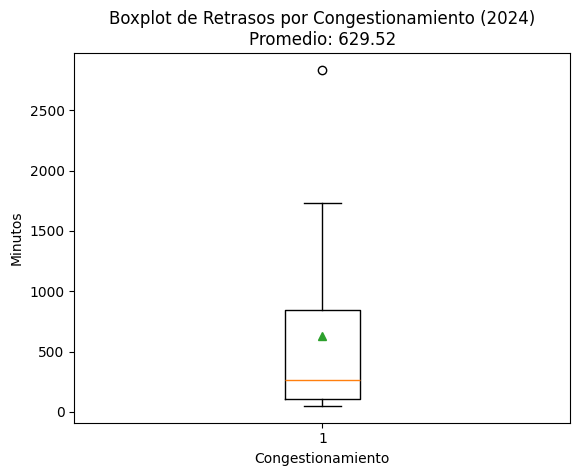

In [43]:
# Crear boxplot para observar el comportamiento de los minutos de congestion JamsDelay
# obtener promedio para mostrarlo en título

mean_value = merged['jams_delay'].mean()
plt.boxplot(merged['jams_delay'], showmeans=True)
plt.title(f'Boxplot de Retrasos por Congestionamiento (2024)\nPromedio: {mean_value:.2f}')
plt.ylabel('Minutos')
plt.xlabel('Congestionamiento')
plt.show()


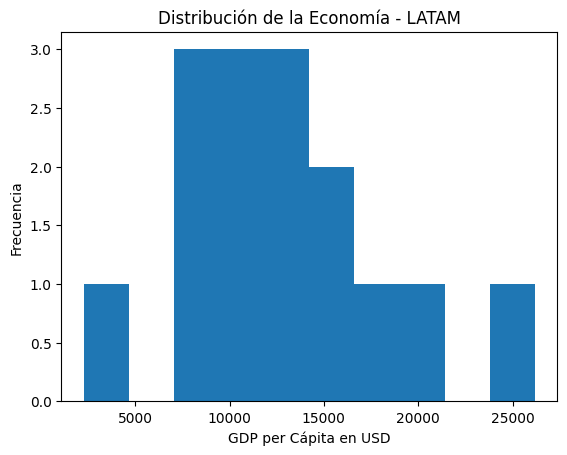

In [44]:
# Crear histograma para ver la distribución de la economía (city_gdp_capita)
plt.hist(merged['city_gdp_capita'])
plt.title('Distribución de la Economía - LATAM')
plt.xlabel('GDP per Cápita en USD')
plt.ylabel('Frecuencia')
plt.show()

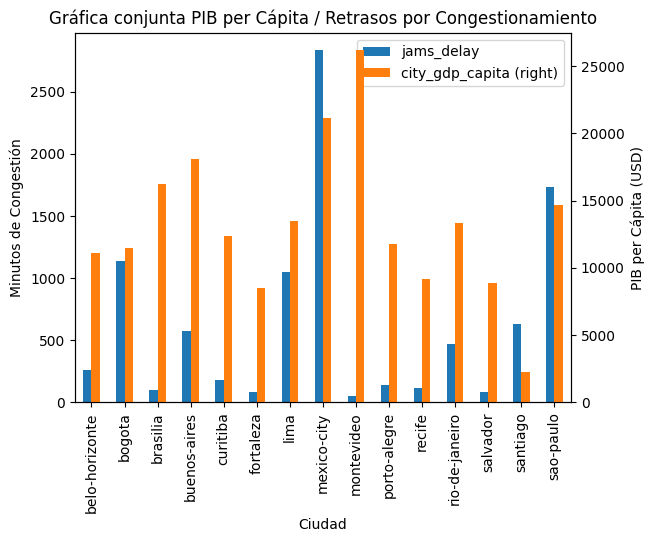

In [45]:
import matplotlib.pyplot as plt

# Gráfico de barras para comparar jams_delay y city_gdp_capita por ciudad
ax = merged.plot(kind='bar', x='city',y=['jams_delay', 'city_gdp_capita'], secondary_y='city_gdp_capita')
plt.title('Gráfica conjunta PIB per Cápita / Retrasos por Congestionamiento')
ax.set_xlabel('Ciudad')
ax.set_ylabel('Minutos de Congestión') # Título para eje Y principal (jams_delay)
ax.right_ax.set_ylabel('PIB per Cápita (USD)') # Título para eje Y secundario (city_gdp_capita)
plt.xticks(rotation=90)
plt.show()

### 🧠 **Reflexión**

* ¿Las ciudades con mayor PIB per cápita también presentan más congestión?

* ¿O sucede lo contrario, o no existe una relación clara?

**No hay una relación clara entre el PIB per cápita y el congestionamiento vehicular, por ejemplo Montevideo tiene un PIB muy alto con un congestionamiento bajo, Ciudad de México tiene un PIB y congestionamiento altos y Santiago tiene un PIB bajo y alto congestionamiento**


---

## 🧩Paso 7: Exportar y documentar resultados

En esta etapa se consolida todo el trabajo: guardar el dataset limpio y crear un resumen que documente los resultados del proyecto.

### 7.1 Guardar dataset final

**🎯Objetivo:**
Generar un CSV limpio, reproducible y con columnas relevantes para análisis posterior.

**Instrucciones**

- Exportar el DataFrame `merged` con el nombre: `ladb_mobility_economy_2024_clean.csv`
- Usar `index=False` para no incluir el índice.


In [46]:
# Exportar el dataset final como CSV
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)

Para poder ver o descargar el archivo generado:   
En el menú lateral que esta a la izquierda, ve hasta la parte de abajo, a la sección de **Exportar dataset** para más información.


---

## ✅ Entregables

1. **Notebook `.ipynb`** con todas las celdas (código + comentarios).
2. **CSV final**: `ladb_mobility_economy_2024_clean.csv`.
3. **Resumen ejecutivo breve** en Markdown (3–5 párrafos).



---

# 🧾 Resumen ejecutivo


**Contexto & objetivo:**  
- Pregunta central del análisis: ¿qué relación existe entre la movilidad urbana (congestión, tiempos de viaje) y la productividad económica (PIB per cápita)?

Se solicita que se analice, con base en datos de movilidad urbana y productividad económica, en qué ciudades de LATAM invertir en infraestructura de transporte para aumentar la productividad y el bienestar de la población. Para ello se cuenta con 2 bases de datos: la primera con datos de movilidad de la cual tomamos el **retraso por congestionamiento** principalmente más otros indicadores de movilidad y en el aspecto económico el **PIB per cápita**.
Con ambas variables podemos responder la pregunta central.

**Cobertura de datos:**  
Se toma como base el año **2024** y 15 ciudades que pertenecen a 7 países de LATAM.

**Metodología (alto nivel):**  
- Se analizan las bases de datos y se encuentra que en la de movilidad se tienen datos no numéricos como son *UpdateTimeUTC y UpdateTimeUTCWeekAgo* por lo que se convierten de texto a fecha (datetime) para su posterior uso.
- En la base de datos económica los datos que vienen como texto y se convierten a numéricos son los siguientes: *City GDP/capita, Unemployment %, PM2.5 (μg/m³) y Population (M)*
- Así mismo, se renombran columnas de ambos data sets para mejorar la claridad.
- En el data set de movilidad (traffic) se añade una columna para año y se filtra por la misma con el año objetivo que es 2024 y a la vez se extraen 2 data sets para trabajar con ellos, los cuales nombramos traffic_2024 y eco_2024
- Se calculan los promedios anuales por ciudad para simplificar el análisis y se agrupan por ciudad, país y año.
- Se unen ambas bases de datos bajo las claves de ciudad y año únicamente con la información que coincida de estas claves en ambos data sets y se conserva la información relevante tanto de movilidad como económica para nuestro análisis.

Se valida visualmente la información con las siguientes gráficas:  
    1.- **Boxplot de retrasos por congestionamiento (JamsDelay)** donde observamos que la media es de 629.52 min y existen outliers donde el valor es de más de 2,500 min cuando el rango normal va de los 100 a los 700 min.  
    2.- **Histograma con la Distribución de la Economía** donde se grafica la frecuencia del PIB per cápita y observamos que la mayor frecuencia se da entre los 6,000 USD y los 14,000 USD con un rango ampliado a 22,000 USD habiendo casos extremos a la baja entre 2,000 USD y 4,000 USD y a la alta entre 24,000 USD y 26,000 USD.  
    3.- **Gráfica de Barras conjunta de PIB per cápita y retrasos por congestionamiento** Donde observamos el comportamiento de ambos durante el 2024 por ciudad de LATAM.  
    
**Hallazgos iniciales:**  
    1.- La ciudad que presenta una alta congestión y una baja productividad es **Santiago de Chile**  
        2.- Las ciudades que muestran una movilidad eficiente en conjunto con una economía fuerte de acuerdo a su PIB son: **Belo Horizonte, Brasilia, Buenos Aires, Curitiba, Fortaleza, Montevideo, Porto Alegre, Recife, Rio de Janeiro y Salvador Bahía**.  
        3.- No hay una relación directa del PIB per cápita vs Movilidad, esto es, a mayor PIB no necesariamente hay más problemas de movilidad y viceversa.  
        4.- Ciudades como **Lima, México y Sao Paulo**, tienen alto PIB pero también problemas de congestionamiento.
  
- Habría que analizar los outliers donde los retrasos por congestionamiento tienen valores superiores a los 2,500 min cuando la media está en 629 min, eso podría afectar el resultado de alguna de las ciudades
- Tal vez se requiere de análisis más profundo en conjunto del porcentaje de desempleo por ciudad y su movilidad pues al existir un alto índice de desempleo la gente no se desplaza
- También se recomienda analizar con base al Traffic Index Live y el Week ago para ver si hay una tendencia o se mantiene estable

**Recomendaciones**  

- ¿Qué ciudad : Bogotá, Lima o Buenos Aires o alguna otra en particular, muestra la mayor correlación significativa entre altos niveles de congestión vehicular y bajos indicadores de productividad económica, sugiriendo ser una ciudad prioritaria para inversión en infraestructura de transporte?
- **Bogotá** sería la ciudad prioritaria para inversión en infraestructura de transporte, aunque **Santiago de Chile** también podría ser una ciudad objetivo por la gran diferencia entre sus altos niveles de congestionamiento y baja productividad económica. Las otras ciudades donde se tiene un problema mayor de congestionamiento son **Ciudad de México y Sao Paulo**.
